In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
day5_path = "../data/analysis_data/APL_Day5_Delay_Risk_Analysis.csv"

df_day6 = pd.read_csv(
    day5_path,
    encoding="cp1252",
    low_memory=False
)

print("Day 5 dataset loaded successfully.")
print("Shape:", df_day6.shape)

Day 5 dataset loaded successfully.
Shape: (180519, 56)


## Day 6 Working Copy

In [3]:
df_day6 = df_day6.copy()

print("Day 6 working copy created.")
print("Shape:", df_day6.shape)

Day 6 working copy created.
Shape: (180519, 56)


## Validate Shipping Mode Data

In [4]:
print(df_day6["Shipping Mode"].value_counts())

Shipping Mode
Standard Class    107752
Second Class       35216
First Class        27814
Same Day            9737
Name: count, dtype: int64


In [5]:
print("Unique Shipping Modes:")
print(df_day6["Shipping Mode"].unique())

print("\nMissing Shipping Mode values:")
print(df_day6["Shipping Mode"].isna().sum())

Unique Shipping Modes:
<ArrowStringArray>
['Standard Class', 'Same Day', 'First Class', 'Second Class']
Length: 4, dtype: str

Missing Shipping Mode values:
0


In [6]:
expected_shipping_modes = {
    "First Class",
    "Second Class",
    "Same Day",
    "Standard Class"
}

shipping_mode_validation = set(
    df_day6["Shipping Mode"].dropna().unique()
).issubset(expected_shipping_modes)

print("Valid shipping modes:", shipping_mode_validation)

Valid shipping modes: True


## Shipping Mode Distribution

In [7]:
shipping_mode_volume = (
    df_day6["Shipping Mode"]
    .value_counts()
    .rename("Total_Shipments")
    .to_frame()
)

shipping_mode_volume["Shipment_Share_%"] = (
    shipping_mode_volume["Total_Shipments"]
    / len(df_day6)
    * 100
).round(2)

display(shipping_mode_volume)

,Total_Shipments,Shipment_Share_%
Shipping Mode,,
Standard Class,107752,59.69
Second Class,35216,19.51
First Class,27814,15.41
Same Day,9737,5.39


## Shipping Mode Delivery Performance

In [8]:
shipping_performance = (
    df_day6
    .groupby("Shipping Mode")
    .agg(
        Total_Shipments=("Shipping Mode", "size"),
        Delayed_Shipments=("Is_Delayed", "sum"),
        Avg_Delay_Days=("Shipping_Delay_Days", "mean"),
        Max_Delay_Days=("Shipping_Delay_Days", "max")
    )
)

shipping_performance["Delay_Rate_%"] = (
    shipping_performance["Delayed_Shipments"]
    / shipping_performance["Total_Shipments"]
    * 100
).round(2)

shipping_performance["Avg_Delay_Days"] = (
    shipping_performance["Avg_Delay_Days"]
    .round(2)
)

display(
    shipping_performance.sort_values(
        "Delay_Rate_%",
        ascending=False
    )
)

,Total_Shipments,Delayed_Shipments,Avg_Delay_Days,Max_Delay_Days,Delay_Rate_%
Shipping Mode,,,,,
First Class,27814,27814,1.00,1,100.00
Second Class,35216,28078,1.99,4,79.73
Same Day,9737,4657,0.48,1,47.83
Standard Class,107752,42851,-0.00,2,39.77


## Scheduled vs Actual Shipping Days

In [9]:
shipping_time_analysis = (
    df_day6
    .groupby("Shipping Mode")
    .agg(
        Avg_Real_Shipping_Days=("Days for shipping (real)", "mean"),
        Avg_Scheduled_Shipping_Days=("Days for shipment (scheduled)", "mean"),
        Min_Real_Shipping_Days=("Days for shipping (real)", "min"),
        Max_Real_Shipping_Days=("Days for shipping (real)", "max")
    )
)

shipping_time_analysis["Avg_Shipping_Gap_Days"] = (
    shipping_time_analysis["Avg_Real_Shipping_Days"]
    - shipping_time_analysis["Avg_Scheduled_Shipping_Days"]
)

shipping_time_analysis = shipping_time_analysis.round(2)

display(shipping_time_analysis)

,Avg_Real_Shipping_Days,Avg_Scheduled_Shipping_Days,Min_Real_Shipping_Days,Max_Real_Shipping_Days,Avg_Shipping_Gap_Days
Shipping Mode,,,,,
First Class,2.00,1.0,2,2,1.00
Same Day,0.48,0.0,0,1,0.48
Second Class,3.99,2.0,2,6,1.99
Standard Class,4.00,4.0,2,6,-0.00


## Shipping Delay Analysis

In [10]:
delay_by_mode = (
    df_day6
    .groupby("Shipping Mode")
    .agg(
        Total_Shipments=("Shipping Mode", "size"),
        Delayed_Shipments=("Is_Delayed", "sum"),
        Avg_Delay_Days=("Shipping_Delay_Days", "mean"),
        Median_Delay_Days=("Shipping_Delay_Days", "median"),
        Max_Delay_Days=("Shipping_Delay_Days", "max")
    )
)

delay_by_mode["Delay_Rate_%"] = (
    delay_by_mode["Delayed_Shipments"]
    / delay_by_mode["Total_Shipments"]
    * 100
).round(2)

delay_by_mode = delay_by_mode.round(2)

display(
    delay_by_mode.sort_values(
        "Delay_Rate_%",
        ascending=False
    )
)

,Total_Shipments,Delayed_Shipments,Avg_Delay_Days,Median_Delay_Days,Max_Delay_Days,Delay_Rate_%
Shipping Mode,,,,,,
First Class,27814,27814,1.00,1.0,1,100.00
Second Class,35216,28078,1.99,2.0,4,79.73
Same Day,9737,4657,0.48,0.0,1,47.83
Standard Class,107752,42851,-0.00,0.0,2,39.77


## Delay Severity by Shipping Mode

In [11]:
severity_by_mode = pd.crosstab(
    df_day6["Shipping Mode"],
    df_day6["Delay_Severity"],
    normalize="index"
).mul(100).round(2)

display(severity_by_mode)

Delay_Severity,Major Delay,Minor Delay,On Time / Early
Shipping Mode,,,
First Class,0.00,100.00,0.00
Same Day,0.00,47.83,52.17
Second Class,59.67,20.06,20.27
Standard Class,20.18,19.59,60.23


In [12]:
severity_counts = pd.crosstab(
    df_day6["Shipping Mode"],
    df_day6["Delay_Severity"]
)

display(severity_counts)

Delay_Severity,Major Delay,Minor Delay,On Time / Early
Shipping Mode,,,
First Class,0,27814,0
Same Day,0,4657,5080
Second Class,21013,7065,7138
Standard Class,21740,21111,64901


## Shipping Mode Risk Comparison

In [13]:
shipping_mode_analysis = (
    df_day6
    .groupby("Shipping Mode")
    .agg(
        Total_Shipments=("Shipping Mode", "size"),
        High_Risk_Shipments=("Late_delivery_risk", "sum"),
        Actual_Delayed_Shipments=("Is_Delayed", "sum"),
        Avg_Delay_Days=("Shipping_Delay_Days", "mean"),
        Avg_Real_Shipping_Days=("Days for shipping (real)", "mean"),
        Avg_Scheduled_Shipping_Days=("Days for shipment (scheduled)", "mean")
    )
)

shipping_mode_analysis["Risk_Rate_%"] = (
    shipping_mode_analysis["High_Risk_Shipments"]
    / shipping_mode_analysis["Total_Shipments"]
    * 100
).round(2)

shipping_mode_analysis["Actual_Delay_Rate_%"] = (
    shipping_mode_analysis["Actual_Delayed_Shipments"]
    / shipping_mode_analysis["Total_Shipments"]
    * 100
).round(2)

shipping_mode_analysis["Shipping_Gap_Days"] = (
    shipping_mode_analysis["Avg_Real_Shipping_Days"]
    - shipping_mode_analysis["Avg_Scheduled_Shipping_Days"]
).round(2)

shipping_mode_analysis["Avg_Delay_Days"] = (
    shipping_mode_analysis["Avg_Delay_Days"]
    .round(2)
)

display(
    shipping_mode_analysis.sort_values(
        "Actual_Delay_Rate_%",
        ascending=False
    )
)

,Total_Shipments,High_Risk_Shipments,Actual_Delayed_Shipments,Avg_Delay_Days,Avg_Real_Shipping_Days,Avg_Scheduled_Shipping_Days,Risk_Rate_%,Actual_Delay_Rate_%,Shipping_Gap_Days
Shipping Mode,,,,,,,,,
First Class,27814,26513,27814,1.00,2.000000,1.0,95.32,100.00,1.00
Second Class,35216,26987,28078,1.99,3.990828,2.0,76.63,79.73,1.99
Same Day,9737,4454,4657,0.48,0.478279,0.0,45.74,47.83,0.48
Standard Class,107752,41023,42851,-0.00,3.995907,4.0,38.07,39.77,-0.00


## Shipping Mode x Market Analysis

In [14]:
mode_market_analysis = (
    df_day6
    .groupby(["Shipping Mode", "Market"])
    .agg(
        Total_Shipments=("Shipping Mode", "size"),
        Delayed_Shipments=("Is_Delayed", "sum"),
        Avg_Delay_Days=("Shipping_Delay_Days", "mean")
    )
)

mode_market_analysis["Delay_Rate_%"] = (
    mode_market_analysis["Delayed_Shipments"]
    / mode_market_analysis["Total_Shipments"]
    * 100
).round(2)

mode_market_analysis["Avg_Delay_Days"] = (
    mode_market_analysis["Avg_Delay_Days"]
    .round(2)
)

display(
    mode_market_analysis
    .sort_values("Delay_Rate_%", ascending=False)
    .head(20)
)

Total_Shipments  Delayed_Shipments  \
Shipping Mode  Market                                             
First Class    Africa                   1727               1727   
               Europe                   7892               7892   
               LATAM                    7886               7886   
               Pacific Asia             6301               6301   
               USCA                     4008               4008   
Second Class   Pacific Asia             8147               6552   
               Africa                   2164               1732   
               Europe                   9861               7887   
               USCA                     5105               4061   
               LATAM                    9939               7846   
Same Day       LATAM                    2650               1354   
               Europe                   2759               1341   
               Africa                    668                317   
               USCA                     1434                647   
               Pacific Asia             2226                998   
Standard Class Africa                   7055               2822   
               Europe                  29740              11869   
               Pacific Asia            24586               9798   
               LATAM                   31119              12334   
               USCA                    15252               6028   

                             Avg_Delay_Days  Delay_Rate_%  
Shipping Mode  Market                                      
First Class    Africa                  1.00        100.00  
               Europe                  1.00        100.00  
               LATAM                   1.00        100.00  
               Pacific Asia            1.00        100.00  
               USCA                    1.00        100.00  
Second Class   Pacific Asia            2.00         80.42  
               Africa                  1.98         80.04  
               Europe                  2.00         79.98  
               USCA                    1.98         79.55  
               LATAM                   1.98         78.94  
Same Day       LATAM                   0.51         51.09  
               Europe                  0.49         48.60  
               Africa                  0.47         47.46  
               USCA                    0.45         45.12  
               Pacific Asia            0.45         44.83  
Standard Class Africa                  0.02         40.00  
               Europe                 -0.01         39.91  
               Pacific Asia           -0.00         39.85  
               LATAM                  -0.01         39.63  
               USCA                   -0.00         39.52

## Minimum-Volume Filters

In [15]:
mode_market_filtered = (
    mode_market_analysis[
        mode_market_analysis["Total_Shipments"] >= 100
    ]
    .sort_values("Delay_Rate_%", ascending=False)
)

display(mode_market_filtered.head(20))

Total_Shipments  Delayed_Shipments  \
Shipping Mode  Market                                             
First Class    Africa                   1727               1727   
               Europe                   7892               7892   
               LATAM                    7886               7886   
               Pacific Asia             6301               6301   
               USCA                     4008               4008   
Second Class   Pacific Asia             8147               6552   
               Africa                   2164               1732   
               Europe                   9861               7887   
               USCA                     5105               4061   
               LATAM                    9939               7846   
Same Day       LATAM                    2650               1354   
               Europe                   2759               1341   
               Africa                    668                317   
               USCA                     1434                647   
               Pacific Asia             2226                998   
Standard Class Africa                   7055               2822   
               Europe                  29740              11869   
               Pacific Asia            24586               9798   
               LATAM                   31119              12334   
               USCA                    15252               6028   

                             Avg_Delay_Days  Delay_Rate_%  
Shipping Mode  Market                                      
First Class    Africa                  1.00        100.00  
               Europe                  1.00        100.00  
               LATAM                   1.00        100.00  
               Pacific Asia            1.00        100.00  
               USCA                    1.00        100.00  
Second Class   Pacific Asia            2.00         80.42  
               Africa                  1.98         80.04  
               Europe                  2.00         79.98  
               USCA                    1.98         79.55  
               LATAM                   1.98         78.94  
Same Day       LATAM                   0.51         51.09  
               Europe                  0.49         48.60  
               Africa                  0.47         47.46  
               USCA                    0.45         45.12  
               Pacific Asia            0.45         44.83  
Standard Class Africa                  0.02         40.00  
               Europe                 -0.01         39.91  
               Pacific Asia           -0.00         39.85  
               LATAM                  -0.01         39.63  
               USCA                   -0.00         39.52

## Shipping Mode Efficiency Ranking

In [16]:
shipping_mode_ranking = shipping_mode_analysis.copy()

shipping_mode_ranking["Efficiency_Rank"] = (
    shipping_mode_ranking["Actual_Delay_Rate_%"]
    .rank(method="dense", ascending=True)
    .astype(int)
)

shipping_mode_ranking = shipping_mode_ranking.sort_values(
    "Efficiency_Rank"
)

display(shipping_mode_ranking)

,Total_Shipments,High_Risk_Shipments,Actual_Delayed_Shipments,Avg_Delay_Days,Avg_Real_Shipping_Days,Avg_Scheduled_Shipping_Days,Risk_Rate_%,Actual_Delay_Rate_%,Shipping_Gap_Days,Efficiency_Rank
Shipping Mode,,,,,,,,,,
Standard Class,107752,41023,42851,-0.00,3.995907,4.0,38.07,39.77,-0.00,1
Same Day,9737,4454,4657,0.48,0.478279,0.0,45.74,47.83,0.48,2
Second Class,35216,26987,28078,1.99,3.990828,2.0,76.63,79.73,1.99,3
First Class,27814,26513,27814,1.00,2.000000,1.0,95.32,100.00,1.00,4


## Visualization 1 - Shipment Volume

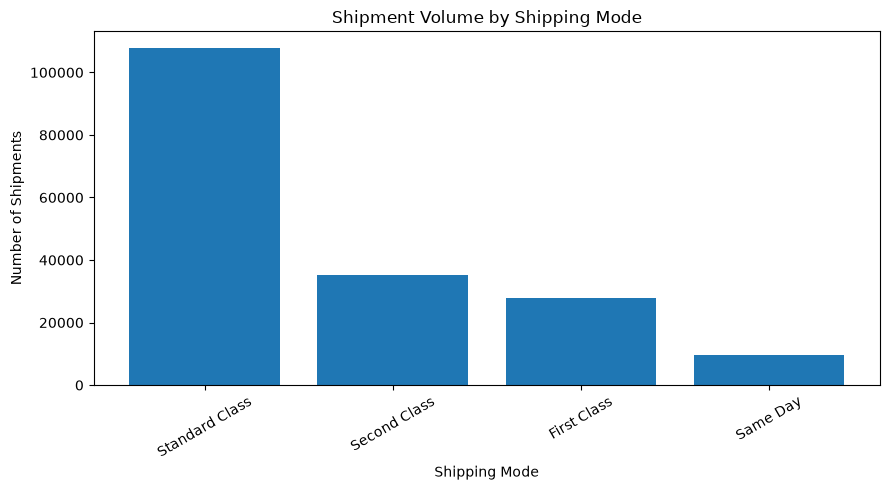

In [17]:
volume = (
    df_day6["Shipping Mode"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

plt.bar(
    volume.index,
    volume.values
)

plt.title("Shipment Volume by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Number of Shipments")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Visualization 2 - Actual Delay Rate

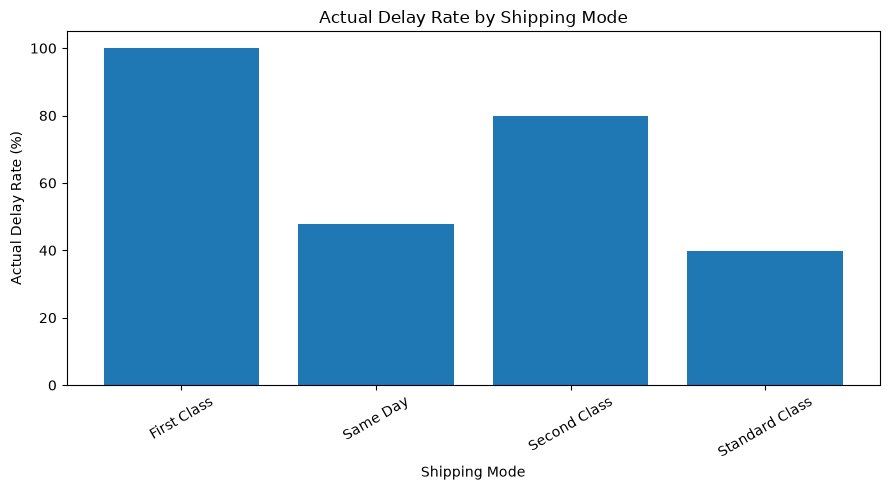

In [18]:
plt.figure(figsize=(9, 5))

plt.bar(
    shipping_mode_analysis.index,
    shipping_mode_analysis["Actual_Delay_Rate_%"]
)

plt.title("Actual Delay Rate by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Actual Delay Rate (%)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Visualization 3 - Schedualed vs Real Shipping Days

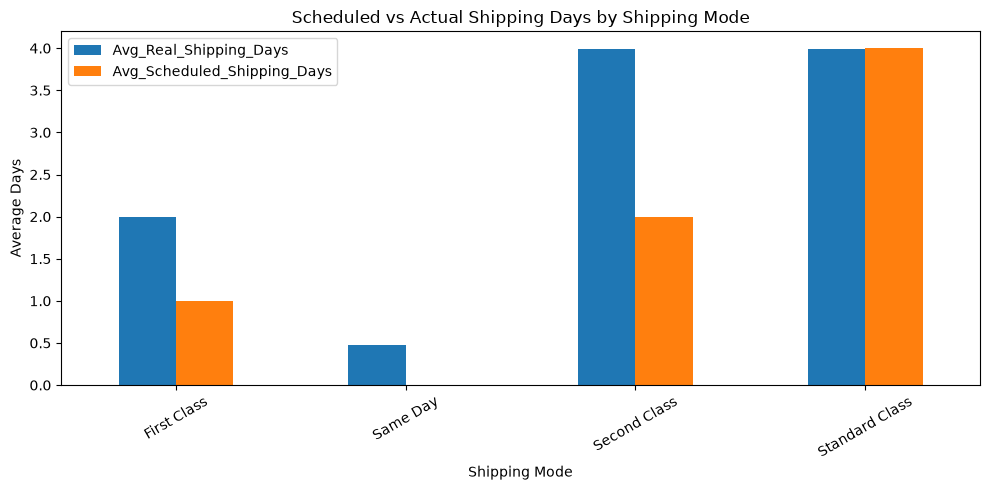

In [19]:
plot_data = shipping_mode_analysis[
    [
        "Avg_Real_Shipping_Days",
        "Avg_Scheduled_Shipping_Days"
    ]
]

plot_data.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Scheduled vs Actual Shipping Days by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Days")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Visualization 4 - Delay Rate vs Shipping Volume 

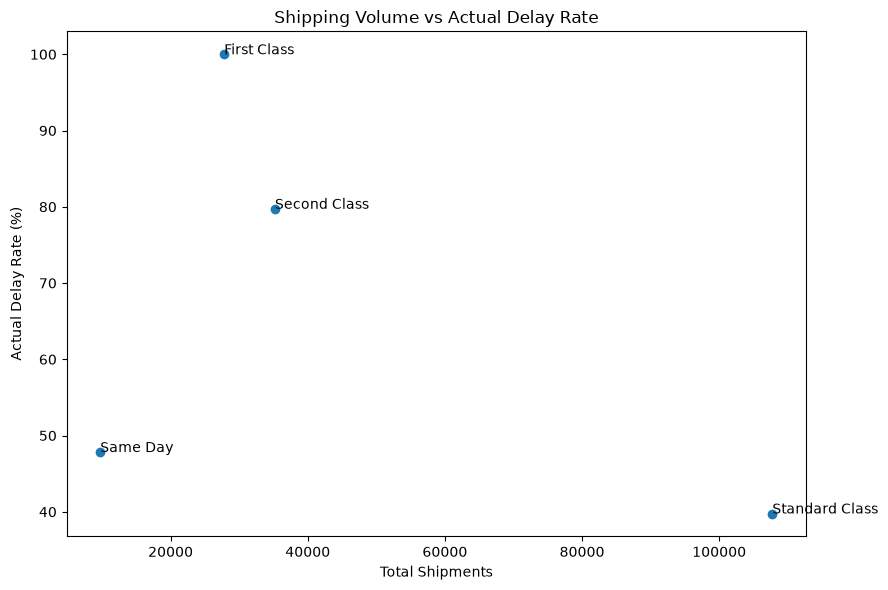

In [20]:
plt.figure(figsize=(9, 6))

plt.scatter(
    shipping_mode_analysis["Total_Shipments"],
    shipping_mode_analysis["Actual_Delay_Rate_%"]
)

for mode in shipping_mode_analysis.index:
    plt.annotate(
        mode,
        (
            shipping_mode_analysis.loc[mode, "Total_Shipments"],
            shipping_mode_analysis.loc[mode, "Actual_Delay_Rate_%"]
        )
    )

plt.title("Shipping Volume vs Actual Delay Rate")
plt.xlabel("Total Shipments")
plt.ylabel("Actual Delay Rate (%)")

plt.tight_layout()
plt.show()

## Day 6 KPI table

In [21]:
day6_kpis = pd.DataFrame({
    "Metric": [
        "Total Shipments",
        "Shipping Modes",
        "Highest Delay Rate Mode",
        "Lowest Delay Rate Mode",
        "Highest Risk Rate Mode",
        "Overall Actual Delay Rate"
    ],
    "Value": [
        len(df_day6),
        df_day6["Shipping Mode"].nunique(),
        shipping_mode_analysis["Actual_Delay_Rate_%"].idxmax(),
        shipping_mode_analysis["Actual_Delay_Rate_%"].idxmin(),
        shipping_mode_analysis["Risk_Rate_%"].idxmax(),
        round(df_day6["Is_Delayed"].mean() * 100, 2)
    ]
})

display(day6_kpis)

,Metric,Value
0,Total Shipments,180519
1,Shipping Modes,4
2,Highest Delay Rate Mode,First Class
3,Lowest Delay Rate Mode,Standard Class
4,Highest Risk Rate Mode,First Class
5,Overall Actual Delay Rate,57.28


## Validation

In [22]:
day6_validation = {
    "Row Count Preserved": len(df_day6) == 180519,

    "No Duplicate Rows":
        df_day6.duplicated().sum() == 0,

    "Shipping Mode Exists":
        "Shipping Mode" in df_day6.columns,

    "No Missing Shipping Mode":
        df_day6["Shipping Mode"].isna().sum() == 0,

    "Valid Shipping Modes":
        set(df_day6["Shipping Mode"].unique()).issubset(
            {
                "First Class",
                "Second Class",
                "Same Day",
                "Standard Class"
            }
        ),

    "Delay Field Exists":
        "Is_Delayed" in df_day6.columns,

    "Delay Days Field Exists":
        "Shipping_Delay_Days" in df_day6.columns
}

day6_validation_report = pd.DataFrame(
    list(day6_validation.items()),
    columns=["Validation", "Status"]
)

display(day6_validation_report)

,Validation,Status
0,Row Count Preserved,True
1,No Duplicate Rows,True
2,Shipping Mode Exists,True
3,No Missing Shipping Mode,True
4,Valid Shipping Modes,True
5,Delay Field Exists,True
6,Delay Days Field Exists,True


In [23]:
if day6_validation_report["Status"].all():
    print("DAY 6 SHIPPING MODE: VALIDATION PASSED")
else:
    print("DAY 6 SHIPPING MODE: CHECK REQUIRED")

DAY 6 SHIPPING MODE: VALIDATION PASSED


## Saving Day 6 Main Dataset

In [24]:
day6_output_path = (
    "../data/analysis_data/"
    "APL_Day6_Shipping_Mode_Analysis.csv"
)

shipping_mode_analysis.to_csv(
    day6_output_path,
    encoding="utf-8"
)

print("Day 6 shipping mode analysis saved successfully.")
print(day6_output_path)

Day 6 shipping mode analysis saved successfully.
../data/analysis_data/APL_Day6_Shipping_Mode_Analysis.csv


## Saving Supporting Outputs

In [25]:
day6_kpi_path = (
    "../data/analysis_data/"
    "APL_Day6_Shipping_Mode_KPIs.csv"
)

day6_kpis.to_csv(
    day6_kpi_path,
    index=False,
    encoding="utf-8"
)

print(day6_kpi_path)

../data/analysis_data/APL_Day6_Shipping_Mode_KPIs.csv


### Validation

In [26]:
day6_validation_path = (
    "../data/analysis_data/"
    "APL_Day6_Shipping_Mode_Validation.csv"
)

day6_validation_report.to_csv(
    day6_validation_path,
    index=False,
    encoding="utf-8"
)

print(day6_validation_path)

../data/analysis_data/APL_Day6_Shipping_Mode_Validation.csv
